In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models

from torchvision import datasets
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

load_dotenv()
# 오류 발생시
# sklearn.set_config(display="text")

True

In [2]:
base_path = r"C:\kdt_0900_lsu\ml\resource\datasets"
Cloud1_path = os.path.join(base_path, "Cloud1")

In [13]:
from kaggle.api.kaggle_api_extended import KaggleApi

api = KaggleApi()
api.authenticate()

os.makedirs(base_path, exist_ok=True)
api.dataset_download_files(r"yeeeengyu/cloud-classification-dataset", path=base_path, unzip=True)

print("다운로드 완료")

Dataset URL: https://www.kaggle.com/datasets/yeeeengyu/cloud-classification-dataset
다운로드 완료


In [3]:
train_path = os.path.join(base_path, "Cloud1", "train")
val_path = os.path.join(base_path, "Cloud1", "val")
test_path = os.path.join(base_path, "Cloud1", "test")

In [4]:
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std)
])

In [5]:
# 이미지 데이터 불러오기
train_dataset = ImageFolder(train_path, transform=train_transform)
val_dataset = ImageFolder(val_path, transform=test_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

In [62]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [7]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: cpu


In [8]:
model1 = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)

In [9]:
model1

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [10]:
for param in model1.parameters():
    param.requires_grad = False

In [11]:
num_classes = len(train_dataset.classes)


model1.classifier = nn.Sequential(
    
    nn.Dropout(p=0.2, inplace=False),
    nn.Linear(model1.classifier[1].in_features, 256),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout (0.4), 
    nn.Linear(256, num_classes)


)

In [ ]:
print(num_classes)

In [30]:
def train_one_epoch_multiclass(model, dataloader, criterion, optimizer, device):
    model.train()
    
    sum_losses = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        
        loss.backward()
        optimizer.step()

        sum_losses += loss.item() * X_batch.size(0)
        y_pred_index = outputs.argmax(dim=1) 
        
        correct += (y_pred_index == y_batch).sum().item()
        total += y_batch.size(0)

    avg_loss = sum_losses / total
    avg_acc = correct / total * 100

    return avg_loss, avg_acc

In [13]:
# def train_one_epoch_multiclass(
#     model, dataloader, criterion, optimizer, device = "cpu"
# ):
#     model.train()

#     sum_losses = 0.0
#     correct = 0
#     total = 0

#     for i, (X_batch, y_batch) in enumerate(dataloader, 1):

#         X_batch = X_batch.to(device)
#         y_batch = y_batch.to(device)

#         optimizer.zero_grad()

#         y_pred = model(X_batch)

#         loss = criterion(y_pred, y_batch)

#         loss.backward()
#         optimizer.step()

#         sum_losses += loss.item() * X_batch.size(0)

#         y_pred_index += y_pred.argmax(dim=1)

#         correct += (y_pred_index == y_batch).sum().item()
#         total += y_batch.size(0)

#         if i % 20 ==0:
#             batch_acc = (
#                 (y_pred_index == y_batch).float().mean().item() * 100
#             )

#             print(
#                 f"[Batch {i}/{len(dataloader)}"
#                 f"Loss: {loss.item():.4f},"
#                 f"Accuracy: {batch_acc:.2f}%"
#             )

#     avg_loss = sum_losses / total
#     avg_acc = correct / total * 100

#     return avg_loss, avg_acc

In [14]:
# @torch.no_grad()
# def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
#     model.eval()

#     sum_losses = 0.0
#     correct = 0
#     total = 0

#     for X_batch, y_batch in dataloader:
#         X_batch = X_batch.to(device)
#         y_batch = y_batch.to(device)

#         outputs = model(X_batch)

#         loss = criterion(outputs, y_batch)
#         sum_losses += loss.item() * X_batxh.size(0)
        
#         y_pred_index = y_pred.argmax(dim=1)
#         correct += (y_batch == y_pred_index).sum().item()
#         total += y_batch.size(0)

#     avg_loss = sum_losses / total
#     avg_acc = correct / total * 100

#     return avg_loss, avg_acc

In [15]:
@torch.no_grad()
def evaluate_multiclass(model, dataloader, criterion, device="cpu"):
    model.eval()

    sum_losses = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in dataloader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        outputs = model(X_batch)
        
        loss = criterion(outputs, y_batch)
        sum_losses += loss.item() * X_batch.size(0)

        y_pred_index = outputs.argmax(dim=1)
        
        correct += (y_batch == y_pred_index).sum().item()
        total += y_batch.size(0)

    avg_loss = sum_losses / total
    avg_acc = correct / total * 100

    return avg_loss, avg_acc

In [19]:
def train_model_multiclass(model, model_name, train_loader, val_loader, criterion, optimizer,epochs,device, save_base_dir):
    save_dir = os.path.join(save_base_dir, model_name)
    os.makedirs(save_dir, exist_ok=True)

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_val_acc = 0.0

    print(f"------------{model_name}학습시작-----------------------")

    for epoch in range(epochs):
        train_loss, train_acc = train_one_epoch_multiclass(model, train_loader, criterion,optimizer, device)

        val_loss, val_acc = evaluate_multiclass(model, val_loader, criterion, device)

        print(
            f"[Epoch {epoch + 1 }/{epoch}]"
            f"Train_Loss: {train_loss:.4f}|"
            f"Train Accuracy: {train_acc:.2f}%"
        )

        print(
            f"[Epoch {epoch + 1}/{epoch}]"
            f"Val Loss:{val_loss:.4f}|"
            f"val Accutacy: {val_acc:.2f}%"
        )
        
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc

            torch.save(
                model.state_dict(),
                os.path.join(save_dir, "best_mode_path")
            )

    torch.save(
        model.state_dict(),
        os.path.join(save_dir, f"last_mode_{epochs}.pth")
    )


    print(f"----------------{model_name}학습종료------------")
    print(f"최고 검증 정확도: {best_val_acc:.2f}%")
    print(f"모델 저장 위치: {save_dir}")

    return history

In [20]:
criterion = nn.CrossEntropyLoss()
optimizer1 = optim.Adam(model1.classifier.parameters(), lr=0.001)

In [21]:
history = train_model_multiclass(
    model=model1,
    model_name = "MobileNetV2-Cloud",
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer1,
    epochs=10,
    device=device,
    save_base_dir = os.path.join(Cloud1_path, "weights")
)

------------MobileNetV2-Cloud학습시작-----------------------
[Epoch 1/0]Train_Loss: 0.4816|Train Accuracy: 80.37%
[Epoch 1/0]Val Loss:0.5442|val Accutacy: 78.18%
[Epoch 2/1]Train_Loss: 0.4355|Train Accuracy: 82.44%
[Epoch 2/1]Val Loss:0.5219|val Accutacy: 80.00%
[Epoch 3/2]Train_Loss: 0.3919|Train Accuracy: 83.75%
[Epoch 3/2]Val Loss:0.4731|val Accutacy: 78.18%
[Epoch 4/3]Train_Loss: 0.4294|Train Accuracy: 81.68%
[Epoch 4/3]Val Loss:0.5034|val Accutacy: 79.09%
[Epoch 5/4]Train_Loss: 0.3806|Train Accuracy: 85.06%
[Epoch 5/4]Val Loss:0.4808|val Accutacy: 80.91%
[Epoch 6/5]Train_Loss: 0.4072|Train Accuracy: 83.42%
[Epoch 6/5]Val Loss:0.4991|val Accutacy: 79.09%
[Epoch 7/6]Train_Loss: 0.3841|Train Accuracy: 83.32%
[Epoch 7/6]Val Loss:0.5465|val Accutacy: 74.55%
[Epoch 8/7]Train_Loss: 0.3487|Train Accuracy: 86.15%
[Epoch 8/7]Val Loss:0.4536|val Accutacy: 83.64%
[Epoch 9/8]Train_Loss: 0.3689|Train Accuracy: 84.84%
[Epoch 9/8]Val Loss:0.5015|val Accutacy: 81.82%
[Epoch 10/9]Train_Loss: 0.3514|Tra

In [37]:
# 모델평가
bast_model_path = os.path.join(Cloud1_path, "weights", "MobilenetV2-Cloud1", "best_model10.pth")
bast_model_path

'C:\\kdt_0900_lsu\\ml\\resource\\datasets\\Cloud1\\weights\\MobilenetV2-Cloud1\\best_model10.pth'

In [44]:
model1.load_state_dict(torch.load(best_model_path, map_location=device))
model1 = model1.to(device)

model1.eval()


MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
  

In [63]:
model1.eval()

test_loss, test_acc = evaluate_multiclass(
    model=model1,
    dataloader=test_loader,
    criterion=criterion,
    device=device
)

print(f"최종 모델의 평가")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

최종 모델의 평가
Test Loss: 0.6348
Test Accuracy: 72.97%


In [58]:
imgs, labels = next(iter(test_dataloader))

print(img.shape)

torch.Size([32, 3, 224, 224])


In [59]:
class_to_idx = train_dataset.class_to_idx
class_dict = dict(enumerate(train_dataset.classes))

In [60]:
model1.eval()
imgs_device = imgs.to(device)

with torch.no_grad():
    preds = model1(imgs_device)
    pred_labels = preds.argmax(dim=1).cpu()

incorrect_samples = []
incorrect_mask = (pred_labels != labels)

if incorrect_mask.any():
    for img, label, pred in zip(imgs[incorrect_mask], labels[incorrect_mask], pred_labels[incorrect_mask]):
        incorrect_samples.append({
            "img": img,
            "true_label": label.item(),
            "pred_label": pred.item()
        })

print(incorrect_samples)

[{'img': tensor([[[-0.4397, -0.4397, -0.4397,  ..., -0.4911, -0.5253, -0.5253],
         [-0.4397, -0.4226, -0.4397,  ..., -0.5082, -0.5424, -0.5424],
         [-0.4397, -0.4226, -0.4226,  ..., -0.5253, -0.5253, -0.5424],
         ...,
         [ 0.8276,  0.8276,  0.8789,  ...,  0.7762,  0.8104,  0.8276],
         [ 0.8789,  0.8447,  0.8961,  ...,  0.7419,  0.7419,  0.7591],
         [ 0.8789,  0.8961,  0.9303,  ...,  0.6734,  0.6734,  0.6563]],

        [[ 0.2052,  0.1877,  0.1877,  ...,  0.2227,  0.2227,  0.2227],
         [ 0.2052,  0.2052,  0.2052,  ...,  0.1702,  0.1702,  0.1702],
         [ 0.2052,  0.2052,  0.2227,  ...,  0.1877,  0.1702,  0.1702],
         ...,
         [ 1.1331,  1.1331,  1.1856,  ...,  1.0630,  1.0805,  1.0805],
         [ 1.1506,  1.1331,  1.1856,  ...,  1.0105,  1.0105,  1.0280],
         [ 1.1681,  1.1331,  1.1856,  ...,  0.9755,  0.9755,  0.9755]],

        [[ 1.1934,  1.1934,  1.1934,  ...,  1.1759,  1.1411,  1.1411],
         [ 1.2631,  1.2457,  1.2631,

확률: 74.08%
예측 확률: 74.08%


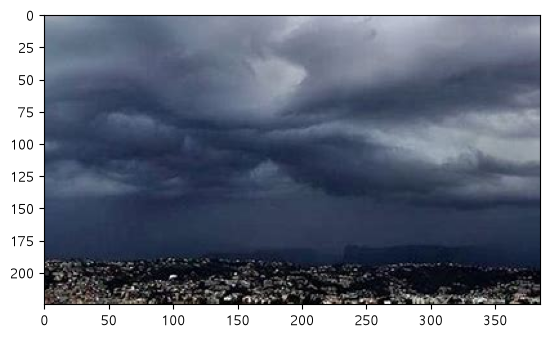

Text(0.5, 1.0, 'Predicated: 비 (74.08%)')

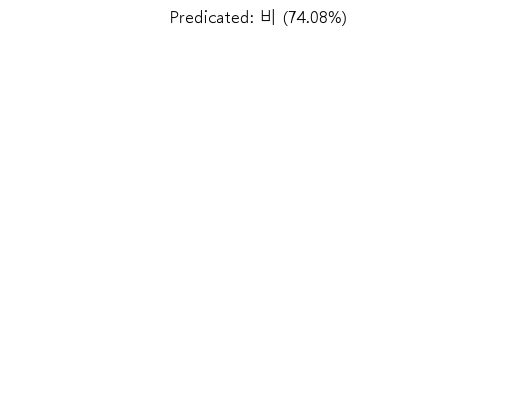

In [72]:
img_path = r"C:\kdt_0900_lsu\ml\resource\datasets\Cloud1\test\비\RainCloud (69).jpg"
img = Image.open(img_path).convert("RGB")


img_tensor = test_transform(img).unsqueeze(0).to(device)

model1.eval()
with torch.no_grad():
    pred = model1(img_tensor)
    probs = torch.softmax(pred, dim=1)
    pred_idx = probs.argmax(dim=1).item()
    prob = probs[0, pred_idx].item() * 100


class_name = train_dataset.classes
pred_class = class_name[pred_idx]

print(f"확률: {prob:.2f}%")
print(f"예측 확률: {prob:.2f}%")

plt.imshow(img)
plt.show()
plt.axis("off")
plt.title(f"Predicated: {pred_class} ({prob:.2f}%)")

In [76]:
y_test = []
y_pred = []

model1.eval()

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)

        outputs = model1(imgs)
        predictions = outputs.argmax(dim=1).cpu()

        y_test.extend(labels.cpu().numpy())
        y_pred.extend(predictions.numpy())

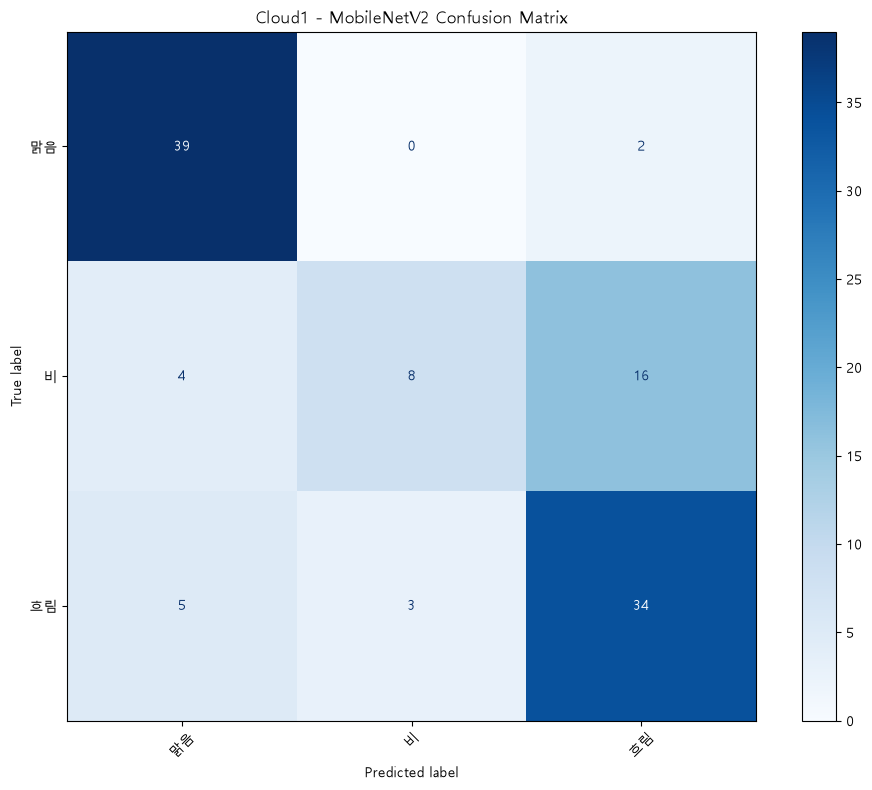

In [78]:
cm = confusion_matrix(y_test, y_pred, labels=list(range(len(train_dataset.classes))))

class_names = train_dataset.classes

display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

fig, ax = plt.subplots(figsize=(10, 8))
display.plot(cmap="Blues", xticks_rotation=45, ax=ax)

plt.title("Cloud1 - MobileNetV2 Confusion Matrix")
plt.tight_layout()
plt.show()